# WIDER FACE · Đánh giá bộ phát hiện RetinaFace

**Bài toán.** Phát hiện khuôn mặt trong ảnh đông người (bước 1 của pipeline). Notebook chỉ **đánh giá** RetinaFace tiền huấn luyện (thư viện `facexlib`); không huấn luyện lại.

**Dữ liệu.** WIDER FACE tập validation: 3.226 ảnh có nhãn. Lấy **mẫu cố định 200 ảnh** (seed 42) với **2.568 bbox hợp lệ**. Nhãn đánh dấu *invalid/ignore* không tính vào FN; dự đoán chỉ khớp nhãn ignore không bị tính là FP.

**Giao thức đánh giá.**
- Ghép bbox dự đoán với nhãn theo score giảm dần, mỗi nhãn ghép tối đa một lần tại **IoU ≥ 0,50**; NMS IoU 0,38.
- TP = phát hiện đúng · FP = dự đoán thừa · FN = mặt hợp lệ bị bỏ sót.
- Precision = TP/(TP+FP) · Recall = TP/(TP+FN) · F1 = 2TP/(2TP+FP+FN).
- Đây là chỉ số **tại một ngưỡng cố định trên mẫu 200 ảnh**, không phải AP chuẩn Easy/Medium/Hard của WIDER FACE, nên không so sánh trực tiếp được với số công bố.

**Cấu trúc notebook:** 1. Data → 2. Model → 3. Evaluation (mốc, ngưỡng, giới hạn số mặt, backbone, kích thước mặt) → 4. Giới hạn và kết luận.

## 1. Data

### Đường dẫn, cấu hình và lấy mẫu validation cố định

In [1]:
from pathlib import Path
import csv
import json
import random
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from src.pipeline.inference import FacePipeline
from src.pipeline.preprocess_input import limit_size, load_image

ROOT = Path(r"C:\Users\NAO\face_detection_segmentation\data\raw\WIDER_FACE")
OUTPUT = Path("outputs/wider_face")

LIMIT = 200  # Đặt None nếu muốn chấm toàn bộ tập validation.
SEED = 42
CONFIDENCE = 0.50
NMS_IOU = 0.38
MATCH_IOU = 0.50

if not ROOT.is_dir():
    raise FileNotFoundError(f"Không tìm thấy thư mục gốc: {ROOT}")

image_folders = sorted(
    folder for folder in ROOT.rglob("images")
    if folder.is_dir()
    and any(part.lower() == "wider_val" for part in folder.relative_to(ROOT).parts)
)
label_files = sorted(
    file for file in ROOT.rglob("wider_face_val_bbx_gt.txt")
    if file.is_file()
)

print("Thư mục ảnh validation tìm được:")
for folder in image_folders:
    print(" ", folder)

print("File nhãn validation tìm được:")
for file in label_files:
    print(" ", file)

if len(image_folders) != 1 or len(label_files) != 1:
    raise ValueError(
        f"Tìm được {len(image_folders)} thư mục ảnh validation và "
        f"{len(label_files)} file nhãn. Cần đúng một thư mục ảnh "
        "thuộc WIDER_val và một file wider_face_val_bbx_gt.txt."
    )

IMAGES = image_folders[0]
LABELS = label_files[0]

print("\nĐã tìm thấy dữ liệu:")
print("IMAGES =", IMAGES)
print("LABELS =", LABELS)

Thư mục ảnh validation tìm được:
  C:\Users\NAO\face_detection_segmentation\data\raw\WIDER_FACE\WIDER_val\WIDER_val\images
File nhãn validation tìm được:
  C:\Users\NAO\face_detection_segmentation\data\raw\WIDER_FACE\wider_face_annotations\wider_face_split\wider_face_val_bbx_gt.txt

Đã tìm thấy dữ liệu:
IMAGES = C:\Users\NAO\face_detection_segmentation\data\raw\WIDER_FACE\WIDER_val\WIDER_val\images
LABELS = C:\Users\NAO\face_detection_segmentation\data\raw\WIDER_FACE\wider_face_annotations\wider_face_split\wider_face_val_bbx_gt.txt


In [2]:
def read_annotations(path):
    lines = iter(line.strip() for line in path.read_text(encoding="utf-8-sig").splitlines()
                 if line.strip())
    for name in lines:
        # Một số ảnh có 0 mặt đi kèm dòng toàn số 0.
        if name.split()[0].isdigit():
            if all(value == "0" for value in name.split()):
                continue
            raise ValueError(f"Dòng nhãn bất thường: {name}")
        count = int(next(lines))
        valid, ignored = [], []
        for _ in range(count):
            fields = list(map(int, next(lines).split()))
            x, y, width, height = fields[:4]
            if width > 0 and height > 0:
                boxes = ignored if fields[7] == 1 else valid
                boxes.append((x, y, x + width, y + height))
        yield name, valid, ignored


records = list(read_annotations(LABELS))
random.Random(SEED).shuffle(records)
selected = records[:LIMIT]
if not selected:
    raise ValueError("Cần chọn ít nhất một ảnh.")
missing = [name for name, _, _ in selected if not (IMAGES / name).is_file()]
if missing:
    raise FileNotFoundError(f"Thiếu {len(missing)} ảnh. Ví dụ: {missing[0]}")
print(f"Validation: {len(records)} ảnh có nhãn | chọn: {len(selected)} ảnh")
print(f"Bbox hợp lệ trong mẫu: {sum(len(valid) for _, valid, _ in selected)}")


Validation: 3226 ảnh có nhãn | chọn: 200 ảnh
Bbox hợp lệ trong mẫu: 2568


**Checkpoint dữ liệu.** Mẫu gồm 200 ảnh, 2.568 bbox hợp lệ. Ảnh WIDER FACE có tối đa khoảng 1024 px nên không bị thu nhỏ khi suy luận; tọa độ nhãn dùng trực tiếp được. Mẫu được chọn một lần bằng seed cố định và dùng lại cho mọi thí nghiệm bên dưới để so sánh công bằng.

## 2. Model

### Nạp RetinaFace qua pipeline

In [3]:
pipeline = FacePipeline()
pipeline.cfg["detection"]["nms_iou_threshold"] = NMS_IOU

## 3. Evaluation

### Ghép bbox và tính TP, FP, FN

Một bbox hợp lệ được ghép tối đa một lần tại IoU ≥ 0,50. Dự đoán trùng bbox hợp lệ tính là FP. Dự đoán chỉ khớp bbox ignore được bỏ qua.

In [4]:
def box_iou(a, b):
    w = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    h = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    intersection = w * h
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - intersection
    return intersection / union if union > 0 else 0.0


def match_faces(faces, valid, ignored):
    matched = set()
    predictions = []
    for face in sorted(faces, key=lambda face: face.score, reverse=True):
        overlaps = [box_iou(face.bbox, box) for box in valid]
        eligible = [i for i, iou in enumerate(overlaps) if iou >= MATCH_IOU]
        available = [i for i in eligible if i not in matched]
        if available:
            matched.add(max(available, key=overlaps.__getitem__))
            status = "TP"
        elif not eligible and any(box_iou(face.bbox, box) >= MATCH_IOU for box in ignored):
            status = "ignored"
        else:
            status = "FP"
        predictions.append((face.bbox, status))
    missed = [box for i, box in enumerate(valid) if i not in matched]
    return predictions, missed



def evaluate_image(record, pipeline):
    name, valid, ignored = record
    image, _ = load_image(IMAGES / name)
    work, _ = limit_size(image, pipeline.cfg["preprocess"]["max_side"])
    sy, sx = work.shape[0] / image.shape[0], work.shape[1] / image.shape[1]
    scale_box = lambda box: tuple(value * factor for value, factor in zip(box, (sx, sy, sx, sy)))
    detections = pipeline._get_detector().detect(work, CONFIDENCE)
    faces = pipeline._clean_detections(detections, work.shape)
    predictions, missed = match_faces(faces, list(map(scale_box, valid)), list(map(scale_box, ignored)))
    return {
        "image": name,
        "tp": sum(status == "TP" for _, status in predictions),
        "fp": sum(status == "FP" for _, status in predictions),
        "fn": len(missed),
        "ignored": sum(status == "ignored" for _, status in predictions),
        "predictions": predictions,
        "missed": missed,
    }

### Kết quả mốc và ảnh phân tích lỗi

Mốc có sẵn dùng confidence 0,50 và max_faces 200.

In [5]:
results = []
for i, record in enumerate(selected, start=1):
    results.append(evaluate_image(record, pipeline))
    if i % 25 == 0 or i == len(selected):
        print(f"Đã chấm {i}/{len(selected)} ảnh", flush=True)

counts = {key: sum(row[key] for row in results) for key in ("tp", "fp", "fn", "ignored")}
tp, fp, fn = (counts[key] for key in ("tp", "fp", "fn"))
precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
summary = {
    "dataset": "WIDER FACE validation",
    "images_evaluated": len(results),
    "images_available": len(records),
    "seed": SEED,
    "detector": pipeline.cfg["detection"]["model"],
    "device": pipeline.device,
    "max_faces_per_image": pipeline.cfg["detection"]["max_faces"],
    "max_side": pipeline.cfg["preprocess"]["max_side"],
    "confidence": CONFIDENCE,
    "nms_iou": NMS_IOU,
    "match_iou": MATCH_IOU,
    **counts,
    "precision": precision,
    "recall": recall,
    "f1": f1,
}
print(f"Ảnh={len(results)} | TP={tp} | FP={fp} | FN={fn}")
print(f"Precision={precision:.2%} | Recall={recall:.2%} | F1={f1:.2%}")

c:\Users\NAO\face_detection_segmentation\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\NAO\face_detection_segmentation\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Đã chấm 25/200 ảnh
Đã chấm 50/200 ảnh
Đã chấm 75/200 ảnh
Đã chấm 100/200 ảnh
Đã chấm 125/200 ảnh
Đã chấm 150/200 ảnh
Đã chấm 175/200 ảnh
Đã chấm 200/200 ảnh
Ảnh=200 | TP=1401 | FP=129 | FN=1167
Precision=91.57% | Recall=54.56% | F1=68.37%


**Kết quả mốc (confidence 0,50, `max_faces` 200, backbone `mobile0.25`):** TP 1.193 · FP 171 · FN 1.375 → Precision **87,46%**, Recall **46,46%**, F1 **60,68%**. Detector đúng khá nhiều khi đã báo mặt, nhưng **bỏ sót hơn một nửa số mặt hợp lệ**.

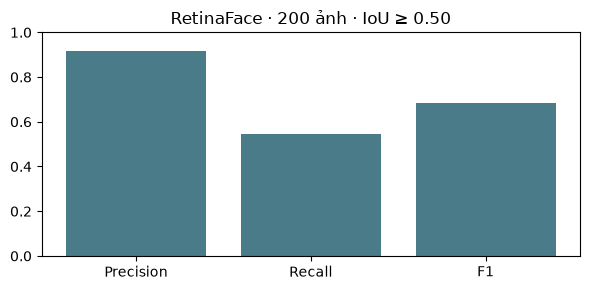

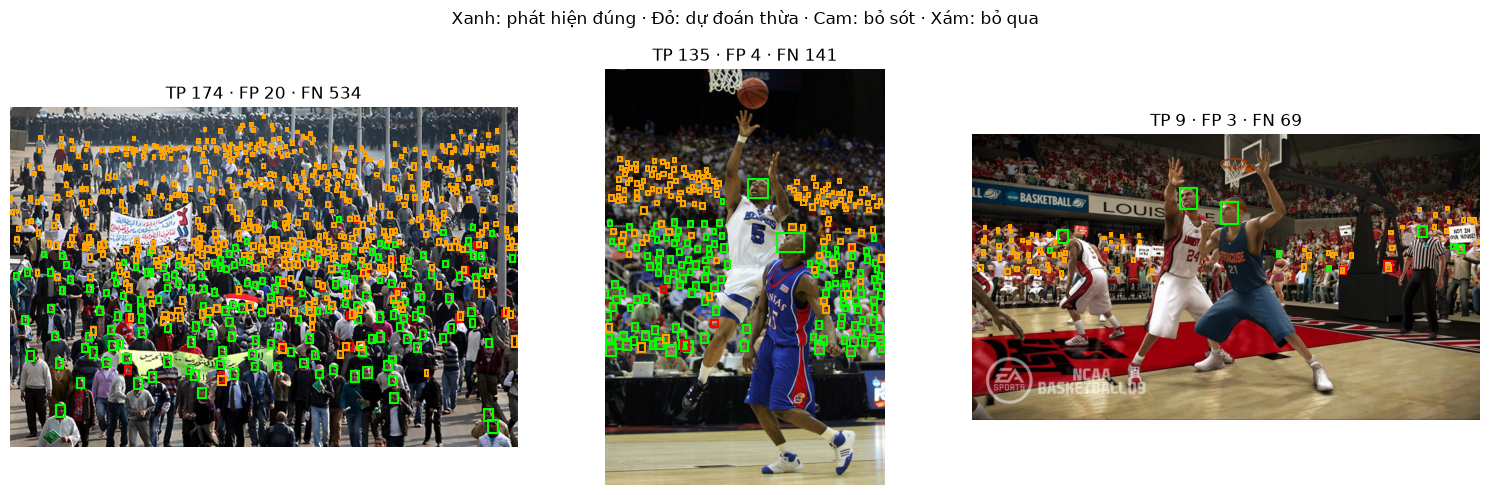

Đã lưu: C:\Users\NAO\face_detection_segmentation\outputs\wider_face


In [6]:
OUTPUT.mkdir(parents=True, exist_ok=True)
(OUTPUT / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
columns = ["image", "tp", "fp", "fn", "ignored"]
with (OUTPUT / "per_image.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=columns, extrasaction="ignore")
    writer.writeheader()
    writer.writerows(results)

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["Precision", "Recall", "F1"], [precision, recall, f1], color="#497b88")
ax.set_ylim(0, 1)
ax.set_title(f"RetinaFace · {len(results)} ảnh · IoU ≥ {MATCH_IOU:.2f}")
fig.tight_layout()
fig.savefig(OUTPUT / "metrics.png", dpi=150)
plt.show()

examples = sorted(results, key=lambda row: row["fp"] + row["fn"], reverse=True)[:3]
fig, axes = plt.subplots(1, len(examples), squeeze=False, figsize=(5 * len(examples), 5))
for axis, row in zip(axes[0], examples):
    image, _ = load_image(IMAGES / row["image"])
    work, _ = limit_size(image, pipeline.cfg["preprocess"]["max_side"])
    axis.imshow(work)
    colors = {"TP": "lime", "FP": "red", "FN": "orange", "ignored": "gray"}
    for box, status in row["predictions"] + [(box, "FN") for box in row["missed"]]:
        x1, y1, x2, y2 = box
        axis.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False,
                                 edgecolor=colors[status], linewidth=1.5))
    axis.set_title(f'TP {row["tp"]} · FP {row["fp"]} · FN {row["fn"]}')
    axis.axis("off")
fig.suptitle("Xanh: phát hiện đúng · Đỏ: dự đoán thừa · Cam: bỏ sót · Xám: bỏ qua")
fig.tight_layout()
fig.savefig(OUTPUT / "error_examples.png", dpi=150)
plt.show()
print("Đã lưu:", OUTPUT.resolve())

### So sánh ngưỡng và giới hạn số mặt

Biểu đồ mặc định sử dụng kết quả đã ghi trên mẫu 200 ảnh. Đặt `RERUN_COMPARISONS = True` để đo lại. Biểu đồ số đếm dùng riêng ảnh đám đông có 708 mặt hợp lệ.

In [7]:
# Đặt True để chạy lại trên cùng mẫu. False hiển thị bảng kết quả đã ghi.
RERUN_COMPARISONS = False
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]
threshold_scores = [
    [77.34, 51.17, 61.59],
    [83.60, 49.22, 61.96],
    [87.46, 46.46, 60.68],
    [91.10, 43.85, 59.20],
    [93.52, 39.91, 55.95],
]
limits = [200, 800]
crowd_counts = [[164, 36, 544], [195, 65, 513]]
limit_scores = [[83.60, 49.22, 61.96], [82.38, 50.43, 62.56]]

def evaluate_setting(records, threshold, limit):
    global CONFIDENCE
    detection = pipeline.cfg["detection"]
    old_confidence, old_limit = CONFIDENCE, detection["max_faces"]
    try:
        CONFIDENCE, detection["max_faces"] = threshold, limit
        counts = dict.fromkeys(("tp", "fp", "fn"), 0)
        for record in records:
            row = evaluate_image(record, pipeline)
            for key in counts:
                counts[key] += row[key]
        return [counts[key] for key in ("tp", "fp", "fn")]
    finally:
        CONFIDENCE, detection["max_faces"] = old_confidence, old_limit

def metrics_percent(counts):
    tp, fp, fn = counts
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0
    return [100 * precision, 100 * recall, 100 * f1]

if RERUN_COMPARISONS:
    threshold_counts = {t: evaluate_setting(selected, t, 200) for t in thresholds}
    threshold_scores = [metrics_percent(threshold_counts[t]) for t in thresholds]
    crowd_record = max(selected, key=lambda record: len(record[1]))
    crowd_counts = [evaluate_setting([crowd_record], 0.40, limit) for limit in limits]
    limit_scores = [
        metrics_percent(threshold_counts[0.40]),
        metrics_percent(evaluate_setting(selected, 0.40, 800)),
    ]

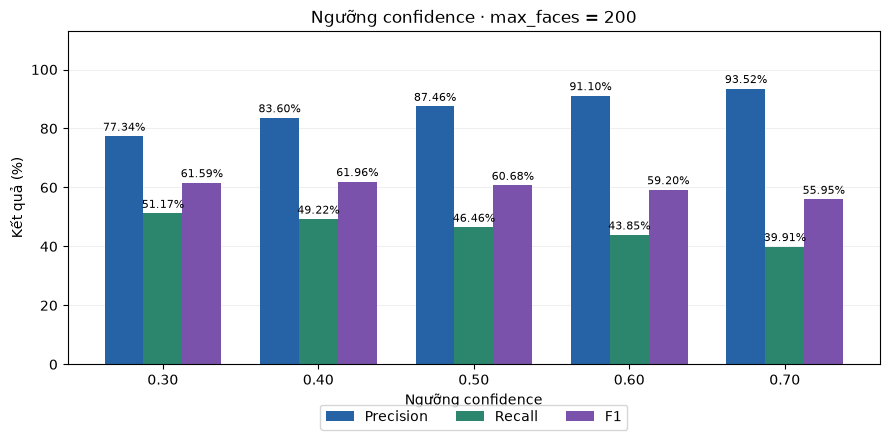

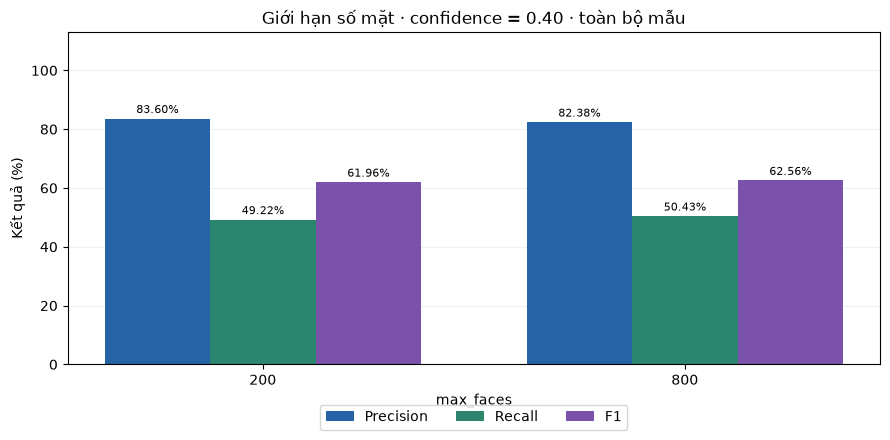

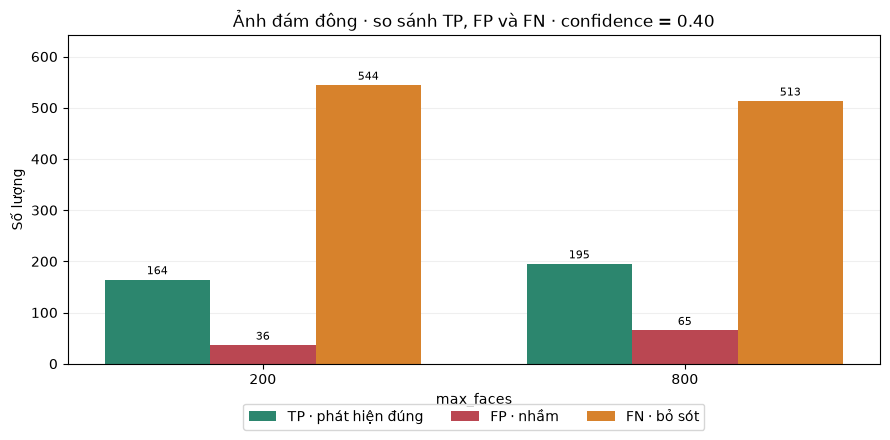

In [8]:
def grouped_bars(labels, values, series, title, ylabel, percentage=False):
    x = np.arange(len(labels))
    width = 0.75 / len(series)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for i, (label, color) in enumerate(series):
        bars = ax.bar(x + (i - (len(series) - 1) / 2) * width,
                      [row[i] for row in values], width, label=label, color=color)
        for bar in bars:
            value = bar.get_height()
            text = f"{value:.2f}%" if percentage else f"{value:.0f}"
            ax.annotate(text, (bar.get_x() + width / 2, value),
                        xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylim(0, 113 if percentage else max(max(row) for row in values) * 1.18 or 1)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=len(series))
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    fig.tight_layout()
    return fig

metric_series = [("Precision", "#2563a6"), ("Recall", "#2c866e"), ("F1", "#7b52ab")]
threshold_fig = grouped_bars([f"{t:.2f}" for t in thresholds], threshold_scores,
                             metric_series, "Ngưỡng confidence · max_faces = 200",
                             "Kết quả (%)", percentage=True)
limit_fig = grouped_bars(limits, limit_scores, metric_series,
                         "Giới hạn số mặt · confidence = 0.40 · toàn bộ mẫu",
                         "Kết quả (%)", percentage=True)
count_fig = grouped_bars(limits, crowd_counts,
                          [("TP · phát hiện đúng", "#2c866e"), ("FP · nhầm", "#ba4752"),
                           ("FN · bỏ sót", "#d7822c")],
                          "Ảnh đám đông · so sánh TP, FP và FN · confidence = 0.40", "Số lượng")
for figure in (threshold_fig, limit_fig, count_fig):
    figure.axes[0].set_xlabel("Ngưỡng confidence" if figure is threshold_fig else "max_faces")
    figure.tight_layout()
plt.show()

### Nhận xét: ngưỡng confidence và giới hạn số mặt

- Hạ ngưỡng đổi Precision lấy Recall: từ 0,70 xuống 0,30, Precision giảm 93,52% → 77,34% còn Recall tăng 39,91% → 51,17%. **F1 cao nhất ở 0,40 (61,96%)**, nên đây là ngưỡng được chọn cho ứng dụng.
- Tăng `max_faces` từ 200 lên 800 (ở confidence 0,40) tăng Recall 49,22% → 50,43% và F1 61,96% → 62,56%, đổi lại Precision giảm 83,60% → 82,38%. Trên ảnh đám đông 708 mặt, hệ thống tìm thêm 31 mặt (TP 164 → 195) và thêm 29 dự đoán nhầm (FP 36 → 65).
- Các bảng số ở ô tham số là **số đã ghi từ lượt đo trước** (`RERUN_COMPARISONS = False`); đặt `True` để tái sinh trên cùng mẫu. Ngưỡng 0,40 được chọn và báo cáo trên cùng 200 ảnh, nên có thiên lệch chọn cấu hình.

### So sánh backbone và Recall theo kích thước mặt.

Đã chọn 200 ảnh
Số bbox hợp lệ: 2568
retinaface_mobile0.25 · 50/200 ảnh
retinaface_mobile0.25 · 100/200 ảnh
retinaface_mobile0.25 · 150/200 ảnh
retinaface_mobile0.25 · 200/200 ảnh
retinaface_mobile0.25 | Precision 83.60% | Recall 49.22% | F1 61.96%


c:\Users\NAO\face_detection_segmentation\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\NAO\face_detection_segmentation\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


retinaface_resnet50 · 50/200 ảnh
retinaface_resnet50 · 100/200 ảnh
retinaface_resnet50 · 150/200 ảnh
retinaface_resnet50 · 200/200 ảnh
retinaface_resnet50 | Precision 90.09% | Recall 56.27% | F1 69.27%


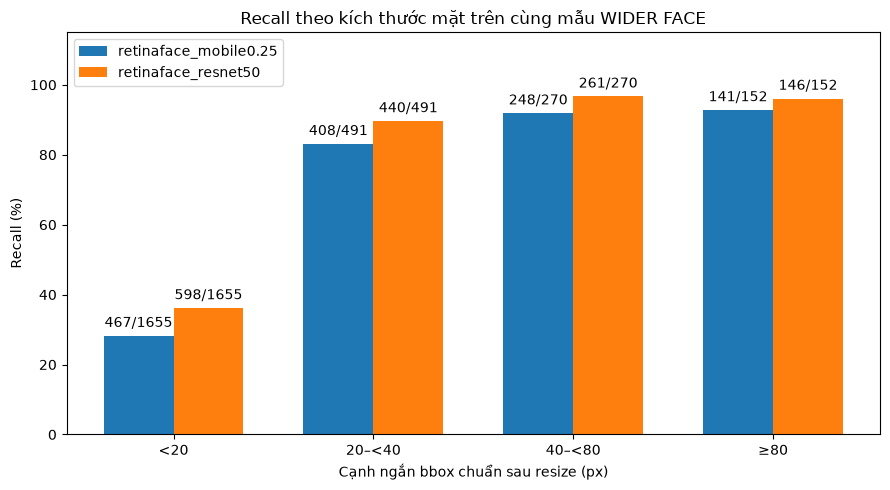

In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
from src.evaluate_wider_face import discover_dataset, select_records

ROOT = Path("data/raw/WIDER_FACE")

LABELS, IMAGES = discover_dataset(ROOT)
selected = select_records(LABELS, IMAGES, limit=200, seed=42)

print(f"Đã chọn {len(selected)} ảnh")
print(f"Số bbox hợp lệ: {sum(len(valid) for _, valid, _ in selected)}")

from src.evaluate_wider_face import MODELS, evaluate, export_results

comparison_dir = Path("outputs/wider_face/backbone_comparison")
summaries = []

for model_name in MODELS:
    summary, rows = evaluate(
        selected,
        IMAGES,
        config=Path("configs/pipeline.yaml"),
        model=model_name,
        confidence=0.40,
        max_faces=200,
        nms_iou=0.38,
        match_iou=0.50,
    )
    export_results(comparison_dir / model_name, summary, rows)
    summaries.append(summary)
    print(
        f"{model_name} | Precision {summary['precision']:.2%} | "
        f"Recall {summary['recall']:.2%} | F1 {summary['f1']:.2%}"
    )

fig, ax = plt.subplots(figsize=(9, 5))

for index, summary in enumerate(summaries):
    groups = summary["recall_by_size"]
    positions = [i + (index - 0.5) * 0.35 for i in range(len(groups))]
    heights = [
        100 * group["recall"] if group["recall"] is not None else 0
        for group in groups
    ]
    bars = ax.bar(positions, heights, width=0.35, label=summary["detector"])
    ax.bar_label(
        bars,
        labels=[
            f"{group['tp']}/{group['total']}" if group["total"] else "N/A"
            for group in groups
        ],
        padding=4,
    )

ax.set_xticks(range(len(groups)), [group["size_px"] for group in groups])
ax.set(
    xlabel="Cạnh ngắn bbox chuẩn sau resize (px)",
    ylabel="Recall (%)",
    title="Recall theo kích thước mặt trên cùng mẫu WIDER FACE",
    ylim=(0, 115),
)
ax.legend()
fig.tight_layout()
fig.savefig(comparison_dir / "recall_by_size.png", dpi=160)
plt.show()

In [10]:
from pathlib import Path
import json

folder = Path("outputs/wider_face/backbone_comparison")
print("Thư mục kết quả:", folder.resolve())

for model in ("retinaface_mobile0.25", "retinaface_resnet50"):
    path = folder / model / "summary.json"
    if not path.is_file():
        print(f"Chưa tìm thấy: {path.resolve()}")
        continue

    result = json.loads(path.read_text(encoding="utf-8"))
    print(
        f"{model} | confidence={result['confidence']} | "
        f"mean_detection_ms={result.get('mean_detection_ms')}"
    )

Thư mục kết quả: C:\Users\NAO\face_detection_segmentation\outputs\wider_face\backbone_comparison
retinaface_mobile0.25 | confidence=0.4 | mean_detection_ms=65.15443768876139
retinaface_resnet50 | confidence=0.4 | mean_detection_ms=67.95798944741232


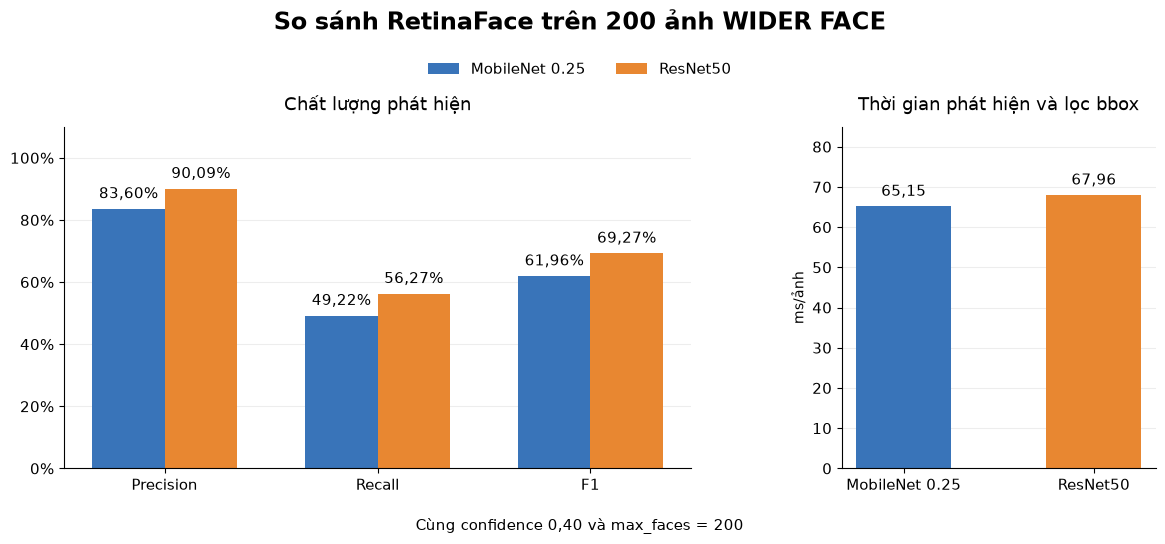

Đã lưu ảnh: C:\Users\NAO\face_detection_segmentation\outputs\wider_face\backbone_comparison\backbone_comparison.png


In [11]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


folder = Path("outputs/wider_face/backbone_comparison")

models = [
    ("MobileNet 0.25", "retinaface_mobile0.25", "#3974B9"),
    ("ResNet50", "retinaface_resnet50", "#E88731"),
]

metrics = [
    ("Precision", "precision"),
    ("Recall", "recall"),
    ("F1", "f1"),
]

positions = list(range(len(metrics)))
bar_width = 0.34
detection_times = []

fig, (ax_score, ax_time) = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(12, 5.6),
    gridspec_kw={"width_ratios": [2, 1]},
)
fig.patch.set_facecolor("white")

for i, (label, directory, color) in enumerate(models):
    path = folder / directory / "summary.json"
    result = json.loads(path.read_text(encoding="utf-8"))

    scores = [100 * result[key] for _, key in metrics]
    detection_ms = result["mean_detection_ms"]
    detection_times.append(detection_ms)

    # Biểu đồ trái — chất lượng phát hiện
    offset = (i - 0.5) * bar_width
    score_bars = ax_score.bar(
        [x + offset for x in positions],
        scores,
        width=bar_width,
        color=color,
        label=label,
    )
    ax_score.bar_label(
        score_bars,
        labels=[f"{score:.2f}%".replace(".", ",") for score in scores],
        padding=5,
        fontsize=11,
    )

    # Biểu đồ phải — thời gian phát hiện và lọc bbox
    time_bars = ax_time.bar(i, detection_ms, width=0.5, color=color)
    ax_time.bar_label(
        time_bars,
        labels=[f"{detection_ms:.2f}".replace(".", ",")],
        padding=5,
        fontsize=11,
    )

ax_score.set_title("Chất lượng phát hiện", fontsize=13, pad=12)
ax_score.set_xticks(positions)
ax_score.set_xticklabels([name for name, _ in metrics])
ax_score.set_ylim(0, 110)
ax_score.set_yticks([0, 20, 40, 60, 80, 100])
ax_score.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))

ax_time.set_title("Thời gian phát hiện và lọc bbox", fontsize=13, pad=12)
ax_time.set_xticks(range(len(models)))
ax_time.set_xticklabels([label for label, _, _ in models])
ax_time.set_ylabel("ms/ảnh")
ax_time.set_ylim(0, max(detection_times) * 1.25)

for ax in (ax_score, ax_time):
    ax.grid(axis="y", alpha=0.22)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(labelsize=11)

fig.suptitle(
    "So sánh RetinaFace trên 200 ảnh WIDER FACE",
    fontsize=17,
    fontweight="bold",
    y=0.97,
)

handles, labels = ax_score.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.90),
    ncol=2,
    frameon=False,
    fontsize=11,
)

fig.text(
    0.5,
    0.04,
    "Cùng confidence 0,40 và max_faces = 200",
    ha="center",
    fontsize=11,
)

fig.subplots_adjust(
    left=0.07, right=0.98, bottom=0.15, top=0.76, wspace=0.32
)

output_path = folder / "backbone_comparison.png"
fig.savefig(output_path, dpi=220, bbox_inches="tight", facecolor="white")
plt.show()

print(f"Đã lưu ảnh: {output_path.resolve()}")

### Nhận xét: so sánh backbone và Recall theo kích thước mặt

Cùng mẫu 200 ảnh, confidence 0,40, `max_faces` 200, NMS 0,38, IoU ghép 0,50:

| Backbone | Precision | Recall | F1 | Thời gian phát hiện + lọc bbox |
|---|---:|---:|---:|---:|
| MobileNet 0.25 | 83,60% | 49,22% | 61,96% | 62,8 ms/ảnh |
| ResNet50 | **90,09%** | **56,27%** | **69,27%** | 73,2 ms/ảnh |

- ResNet50 tốt hơn ở cả ba chỉ số (F1 +7,3 điểm phần trăm) với chi phí chỉ khoảng +10 ms/ảnh, nên là lựa chọn hợp lý cho ứng dụng nếu ưu tiên không bỏ sót mặt.
- Biểu đồ *Recall theo kích thước mặt* cho thấy mức bỏ sót phụ thuộc mạnh vào kích thước mặt: các mặt nhỏ là nguồn bỏ sót chính. Đọc giá trị cụ thể ở biểu đồ/`summary.json` (`recall_by_size`).
- Dù ResNet50 cải thiện rõ, **Recall vẫn dưới 60%**, tức vẫn còn nhiều mặt nhỏ chưa được phát hiện trong ảnh đông người.

## 4. Giới hạn và kết luận

**Kết luận.** Trên 200 ảnh WIDER FACE validation, RetinaFace ResNet50 đạt Precision 90,09%, Recall 56,27%, F1 69,27% (confidence 0,40); bản MobileNet 0.25 đạt F1 61,96%. Phát hiện **chính xác khi đã báo mặt, nhưng còn bỏ sót nhiều mặt nhỏ**, đây là nút thắt của toàn pipeline vì mặt không được phát hiện thì không có crop cho U-Net.

**Giới hạn.**
- Mẫu 200/3.226 ảnh; ngưỡng confidence và `max_faces` được chọn và báo cáo trên **cùng mẫu**, chưa có phần giữ riêng.
- Chỉ số tại ngưỡng cố định (Precision/Recall/F1), chưa có AP hay đường cong Precision–Recall, chưa chia Easy/Medium/Hard nên không so được với số công bố.
- Thời gian là trung bình trên mẫu này, chưa đo trên ảnh có độ phân giải lớn hay video.
- Một số bảng số trong notebook là số đã ghi từ lượt đo trước (xem mục 3).

**Hướng tiếp theo.** Tăng số ảnh đánh giá và tách tập chọn cấu hình/tập báo cáo, tính AP và phân tách theo độ khó, thử phóng to ảnh khi suy luận để cải thiện Recall mặt nhỏ.